# Labor Market Polarization under Differential AI Exposure
### Notebook 3: Statistical Model Checking and Monte Carlo Analysis

**Course:** Computational Economics (A.Y. 2025-2026)  
**Institutions:** Sant'Anna School of Advanced Studies & University of Pisa  
**Professors:** Prof. G. Fagiolo, Prof. A. Roventini, Prof. A. Vandin  

**Students:** 
* Lucia D'Amore  
* Nora Donelli  
* Silvia Pagliarulo  
* Sofia Perondi  

---

### Notebook Overview
This notebook takes the Axelrod (mean-field imitation) specification introduced in Notebook 1 as Model 2, and subjects it to two complementary layers of statistical analysis:

1. **Statistical Model Checking (Part I).** A MultiVeStA-style transient estimator is wrapped around `AutomationModel` and used to estimate the expected trajectory of the emergent observables with a *guaranteed* confidence interval, choosing the number of replications adaptively.
2. **Monte Carlo analysis (Part II).** The model is replicated over N_RUNS seeds (depending on the SMC results in Part I) under four parameter configurations, obtained by crossing the precautionary buffer (`buffer_months` in {3, 0}) with the hiring-patience decay (`patience_decay` in {0.05, 0.02}). The configuration `buffer_months = 3`, `patience_decay = 0.05` is the main specification; the remaining three provide a robustness grid.

Throughout, the imitation coefficient is held at its calibrated value `gamma = 0.032` (Bass, 1969): the entire notebook concerns the Axelrod specification with `gamma > 0`.

## The Axelrod specification (Model 2)

The model is reproduced unchanged from Notebook 1 so that this notebook runs standalone. Only the Axelrod branch is retained: the per-firm AI-arrival hazard carries the mean-field imitation term
$$\lambda_i(t) = \lambda_0 + \gamma \, F(t), \qquad P_i(t) = 1 - e^{-\lambda_i(t)},$$
where $F(t)$ is the share of already-automated firms at the start of the step. The innovation coefficient $\lambda_0 = 0.010097$ (Bass "p") and the imitation coefficient $\gamma = 0.032$ (Bass "q") are the calibrated values; setting $\gamma = 0$ would nest the pure-Poisson Model 1, which is not considered here.

The data collector exposes only the subset of Notebook 1's reporters required by the analyses below (savings inequality, polarization, unemployment, wages and savings by seniority, reskilling among the displaced, and adoption), keeping the accounting identical while shortening the code.

In [1]:
# Core libraries and consistent plotting style
import warnings
warnings.filterwarnings("ignore")          # silences all-NaN slices before any worker is displaced
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import stats
from mesa import Agent, Model
from mesa.datacollection import DataCollector

mpl.rcParams.update({
    "font.family":      "serif",
    "font.serif":       ["Palatino Linotype", "Palatino", "Book Antiqua", "serif"],
    "mathtext.fontset": "stix",
    "axes.titlesize":   12,
    "axes.labelsize":   11,
    "xtick.labelsize":  10,
    "ytick.labelsize":  10,
    "legend.fontsize":  9,
    "figure.dpi":       120,
})

# Shared constants
SEED     = 42
N_STEPS  = 150
LAMBDA_0 = 0.010097   # Bass innovation coefficient p (calibrated in Notebook 2 of the paper)
GAMMA    = 0.032      # Bass imitation coefficient q (Axelrod mean-field pressure)


### Agents and model
The agent and model code below is identical to the Axelrod specification of Notebook 1; the inline comments flag the economic role of each mechanism.

In [2]:
# Worker and firm agents (reproduced from Notebook 1, Axelrod specification)

class WorkerAgent(Agent):
    """Worker labelled Junior or Senior, subject to AI-driven displacement."""

    def __init__(self, model, seniority, initial_savings):
        super().__init__(model=model)
        self.seniority = seniority
        self.savings = initial_savings
        self.skills = 1.0
        self.employed = True
        self.status = "Employed"
        self.employer = None
        self.unemployment_duration = 0
        self.did_retrain = False
        self.was_ever_displaced = False
        self.hired_without_retraining = False
        self.retraining_timer = 0
        self.last_wage = model.wage_baseline
        self.savings_rate = model.savings_rate_base
        self.hiring_weight = 1.0
        self.retraining_decision_made = False

    def receive_wage(self, wage):
        """Buffer-stock savings rule: the rate rises with the wage relative to
        the economy-wide baseline (Deaton, 1991; Carroll, 1997). The consumed
        share flows back to the employer's capital, closing the monetary loop."""
        self.last_wage = wage
        wage_ratio = wage / self.model.wage_baseline
        raw_rate = self.model.savings_rate_base + self.model.beta_savings * (wage_ratio - 1)
        self.savings_rate = min(max(raw_rate, self.model.savings_rate_min),
                                self.model.savings_rate_max)
        self.savings += wage * self.savings_rate
        if self.employer:
            self.employer.capital += wage * (1 - self.savings_rate)

    def step(self):
        # Employed workers are passive within the worker phase.
        if self.status == "Employed":
            return

        self.unemployment_duration += 1

        # Subsistence consumption, capped at available savings (no borrowing).
        consumption = min(self.model.subsistence_cost, max(self.savings, 0.0))
        self.savings -= consumption
        per_firm = consumption / len(self.model.firms_pool)
        for firm in self.model.firms_pool:
            firm.capital += per_firm

        # Retraining in progress: on completion, skills and hiring signal rise.
        if self.status == "Retraining":
            self.retraining_timer -= 1
            if self.retraining_timer <= 0:
                self.skills += self.model.skill_gain
                self.hiring_weight = self.model.retrain_signal_weight
                self.did_retrain = True
                self.status = "Unemployed"
            return

        # Retraining decision, evaluated once at first displacement (buffer-stock
        # threshold): only workers above Theta can afford Path A.
        if self.status == "Unemployed" and not self.retraining_decision_made:
            self.retraining_decision_made = True
            if self.savings >= self.model.retraining_threshold:
                self.status = "Retraining"
                self.retraining_timer = self.model.retraining_duration
                fee = self.model.training_cost
                self.savings -= fee
                per_firm_f = fee / len(self.model.firms_pool)
                for firm in self.model.firms_pool:
                    firm.capital += per_firm_f


class FirmAgent(Agent):
    """Firm with a per-firm AI-adoption hazard (innovation + imitation),
    learning-by-doing productivity, and profit-sharing markup wages."""

    def __init__(self, model, initial_capital):
        super().__init__(model=model)
        self.capital = initial_capital
        self.employees_list = []
        self.firm_revenue = model.revenue_0
        self.ai_unlocked = False
        self.already_fired = False
        self.productivity = 1.0
        self.automation_level = 0.0
        self.desired_skill = model.desired_skill
        self.patience = 0
        self.target_size = 0
        self.base_productivity = 1.0

    # AI ARRIVAL: Poisson innovation + mean-field imitation (Axelrod / Bass, 1969)
    def check_ai_arrival(self):
        """lambda_i(t) = lambda_0 + gamma * F(t); F(t) is fixed once per step."""
        if not self.ai_unlocked:
            rate = self.model.lambda_ai + self.model.gamma * self.model.adoption_share
            p = 1 - np.exp(-rate)
            if self.random.random() < p:
                self.ai_unlocked = True

    # PRODUCTIVITY: learning-by-doing, scaled by current workforce skill
    def update_productivity(self):
        if self.ai_unlocked:
            self.base_productivity += self.model.rho * (self.model.pi_max - self.base_productivity)
            media_skills = (sum(w.skills for w in self.employees_list) / len(self.employees_list)
                            if self.employees_list else 1.0)
            self.productivity = self.base_productivity * media_skills

    # REVENUE: net of the fixed AI operating cost, floored at zero
    def update_revenue(self):
        revenue_0 = self.model.revenue_0
        if self.ai_unlocked:
            gross = revenue_0 * self.productivity
            self.firm_revenue = max(gross - self.model.ca_fixed, 0.0)
        else:
            self.firm_revenue = revenue_0

    # WAGES: profit-sharing markup, with a penalty for Path-B (unreskilled) re-hires
    def distribute_wages(self):
        w0 = self.model.wage_baseline
        if self.firm_revenue > self.model.revenue_0:
            base_wage = w0 * (1 + self.model.theta *
                        (self.firm_revenue - self.model.revenue_0) / self.model.revenue_0)
        else:
            base_wage = w0
        for worker in self.employees_list:
            current_wage = (base_wage * self.model.underemployment_penalty
                            if worker.hired_without_retraining else base_wage)
            self.capital -= current_wage
            worker.receive_wage(current_wage)

    # FIRING: one-off displacement by AI exposure (Brynjolfsson, Chandar & Chen, 2025)
    def firing_rule(self):
        self.automation_level = 1.0
        for worker in list(self.employees_list):
            exposure = 0.60 if worker.seniority == "Junior" else 0.02   # calibrated p_J, p_S
            if self.random.random() < exposure:
                self.model.cumulative_displaced += 1
                worker.was_ever_displaced = True
                if worker.seniority == "Junior":
                    self.model.fired_junior_step += 1
                else:
                    self.model.fired_senior_step += 1
                worker.employed = False
                worker.status = "Unemployed"
                worker.employer = None
                self.employees_list.remove(worker)

    # HIRING: signalling draw plus a patience-eroded skill reservation (Spence, 1973)
    def evaluate_hiring(self):
        if not self.ai_unlocked:
            return
        if self.capital < self.model.wage_baseline * self.model.hire_buffer:
            return
        if len(self.employees_list) >= self.target_size:
            return
        pool = self.model.get_unemployed_pool()
        if not pool:
            return
        weights = [w.hiring_weight for w in pool]
        candidate = self.random.choices(pool, weights=weights, k=1)[0]
        reservation = self.desired_skill - self.patience * self.model.patience_decay
        if candidate.skills >= reservation:
            self.hire(candidate)
            self.patience = 0
        else:
            self.patience += 1

    def hire(self, worker):
        worker.employer = self
        worker.employed = True
        worker.status = "Employed"
        worker.hired_without_retraining = not worker.did_retrain
        if worker.did_retrain:
            self.model.hired_skilled_step += 1
        else:
            self.model.hired_unskilled_step += 1
        self.employees_list.append(worker)

    def step(self):
        self.check_ai_arrival()
        self.update_productivity()
        self.update_revenue()
        self.capital += self.firm_revenue
        self.distribute_wages()
        if self.ai_unlocked and not self.already_fired:
            self.firing_rule()
            self.already_fired = True
        self.evaluate_hiring()


In [3]:
# The market: AI adoption, stochastic displacement, and skill-based hiring

class AutomationModel(Model):
    def __init__(self, num_firms=100, num_workers=1000, initial_firm_capital=1000.0,
                 initial_worker_savings=0.0, wage_baseline=20.0, savings_rate=0.20,
                 beta_savings=0.058, savings_rate_min=0.0, savings_rate_max=0.25,
                 revenue_0=400.0, senior_ratio=0.3, lambda_ai=0.010097,
                 gamma=0.0320,          # Axelrod/Bass imitation coefficient (>0 in this notebook)
                 rho=0.017, pi_max=1.362, ca_fixed=1.22, theta=0.35, hire_buffer=3.0,
                 patience_decay=0.05, desired_skill=1.3, subsistence_cost=10,
                 training_cost=60, retrain_signal_weight=2.0, buffer_months=3, seed=None):
        super().__init__(seed=seed)

        # Exogenous parameters
        self.wage_baseline = wage_baseline
        self.savings_rate_base = savings_rate
        self.beta_savings = beta_savings
        self.savings_rate_min = savings_rate_min
        self.savings_rate_max = savings_rate_max
        self.revenue_0 = revenue_0
        self.lambda_ai = lambda_ai
        self.gamma = gamma
        self.adoption_share = 0.0
        self.rho = rho
        self.pi_max = pi_max
        self.ca_fixed = ca_fixed
        self.theta = theta
        self.hire_buffer = hire_buffer
        self.patience_decay = patience_decay
        self.desired_skill = desired_skill
        self.subsistence_cost = subsistence_cost
        self.retraining_duration = 3
        self.training_cost = training_cost
        self.buffer_months = buffer_months
        # Endogenous retraining threshold Theta = retraining living cost + fee + precautionary buffer
        self.retraining_threshold = (self.retraining_duration * self.subsistence_cost
                                      + self.training_cost
                                      + self.wage_baseline * self.buffer_months)
        self.skill_gain = 0.3
        self.underemployment_penalty = 0.85
        self.current_step = 0
        self.retrain_signal_weight = retrain_signal_weight
        self.cumulative_displaced = 0
        self.hired_skilled_step = 0
        self.hired_unskilled_step = 0
        self.fired_junior_step = 0
        self.fired_senior_step = 0

        # Data collection (subset of Notebook 1's reporters used by Parts I-II).
        # Wage/savings-by-seniority means are conditioned on employment.
        emp = lambda m, s: [w for w in m.agents if isinstance(w, WorkerAgent)
                            and w.seniority == s and w.status == "Employed"]
        allw = lambda m, s: [w for w in m.agents if isinstance(w, WorkerAgent) and w.seniority == s]
        self.datacollector = DataCollector(model_reporters={
            "Gini":                 lambda m: m.calculate_gini,
            "Gini_Savings_Junior":  lambda m: m.calculate_gini_savings_junior,
            "Polarization":         lambda m: m.calculate_enhanced_polarization,
            "Firms_Automated":      lambda m: sum(1 for f in m.agents
                if isinstance(f, FirmAgent) and f.ai_unlocked),
            "N_Unemployed":         lambda m: sum(1 for w in m.agents
                if isinstance(w, WorkerAgent) and w.status == "Unemployed"),
            "Mean_Wage_Junior":     lambda m: (np.mean([w.last_wage for w in emp(m, "Junior")])
                if emp(m, "Junior") else np.nan),
            "Mean_Wage_Senior":     lambda m: (np.mean([w.last_wage for w in emp(m, "Senior")])
                if emp(m, "Senior") else np.nan),
            "Mean_Savings_Junior":  lambda m: (np.mean([w.savings for w in allw(m, "Junior")])
                if allw(m, "Junior") else np.nan),
            "Mean_Savings_Senior":  lambda m: (np.mean([w.savings for w in allw(m, "Senior")])
                if allw(m, "Senior") else np.nan),
            "Frac_Reskilled_AmongDisplaced": lambda m: (
                sum(1 for w in m.agents if isinstance(w, WorkerAgent)
                    and w.was_ever_displaced and w.did_retrain)
                / sum(1 for w in m.agents if isinstance(w, WorkerAgent) and w.was_ever_displaced)
                if any(isinstance(w, WorkerAgent) and w.was_ever_displaced for w in m.agents)
                else np.nan),
        })

        # Create firms, then workers assigned to firms (bipartite labor graph)
        for _ in range(num_firms):
            FirmAgent(self, initial_firm_capital)
        self.firms_pool = [a for a in self.agents if isinstance(a, FirmAgent)]
        for _ in range(num_workers):
            seniority = "Senior" if self.random.random() < senior_ratio else "Junior"
            worker = WorkerAgent(self, seniority, initial_worker_savings)
            firm = self.random.choice(self.firms_pool)
            worker.employer = firm
            firm.employees_list.append(worker)
        for f in self.firms_pool:
            f.target_size = len(f.employees_list)

        self.running = True
        self.datacollector.collect(self)

    def get_unemployed_pool(self):
        """Workers available for hire: unemployed and not currently retraining."""
        return [w for w in self.agents
                if isinstance(w, WorkerAgent) and w.status == "Unemployed"]

    # Metrics
    @property
    def calculate_gini(self):
        """Gini coefficient over all worker savings (0 = equality)."""
        x = sorted(w.savings for w in self.agents if isinstance(w, WorkerAgent))
        n = len(x)
        if sum(x) == 0:
            return 0.0
        b = sum(xi * (n - i) for i, xi in enumerate(x)) / (n * sum(x))
        return 1 + (1 / n) - 2 * b

    @property
    def calculate_enhanced_polarization(self):
        """Senior/Junior mean-savings ratio; equals 1.0 under no differential exposure."""
        workers = [w for w in self.agents if isinstance(w, WorkerAgent)]
        if not workers:
            return 1.0
        senior_s = [w.savings for w in workers if w.seniority == "Senior"]
        junior_s = [w.savings for w in workers if w.seniority == "Junior"]
        if not senior_s or not junior_s:
            return 1.0
        mu_j = np.mean(junior_s)
        return np.mean(senior_s) / mu_j if mu_j > 0 else np.nan

    @property
    def calculate_gini_savings_junior(self):
        """Gini coefficient over Junior workers' savings only."""
        x = sorted(w.savings for w in self.agents
                   if isinstance(w, WorkerAgent) and w.seniority == "Junior")
        n = len(x)
        if sum(x) == 0:
            return 0.0
        b = sum(xi * (n - i) for i, xi in enumerate(x)) / (n * sum(x))
        return 1 + (1 / n) - 2 * b

    # Step: firms act first (revenue, wages, fire, hire), then workers react
    def step(self):
        self.current_step += 1
        self.hired_skilled_step = 0
        self.hired_unskilled_step = 0
        self.fired_junior_step = 0
        self.fired_senior_step = 0
        # F(t) computed once, before firms act (synchronous mean field)
        self.adoption_share = sum(1 for f in self.firms_pool if f.ai_unlocked) / len(self.firms_pool)
        self.agents.select(agent_type=FirmAgent).shuffle_do("step")
        self.agents.select(agent_type=WorkerAgent).shuffle_do("step")
        self.datacollector.collect(self)


### Smoke test
A single deterministic run (`SEED = 42`, `gamma = 0.032`, main-spec parameters) over the standard horizon confirms that the carried-over model executes and produces the expected qualitative behaviour before any replication.

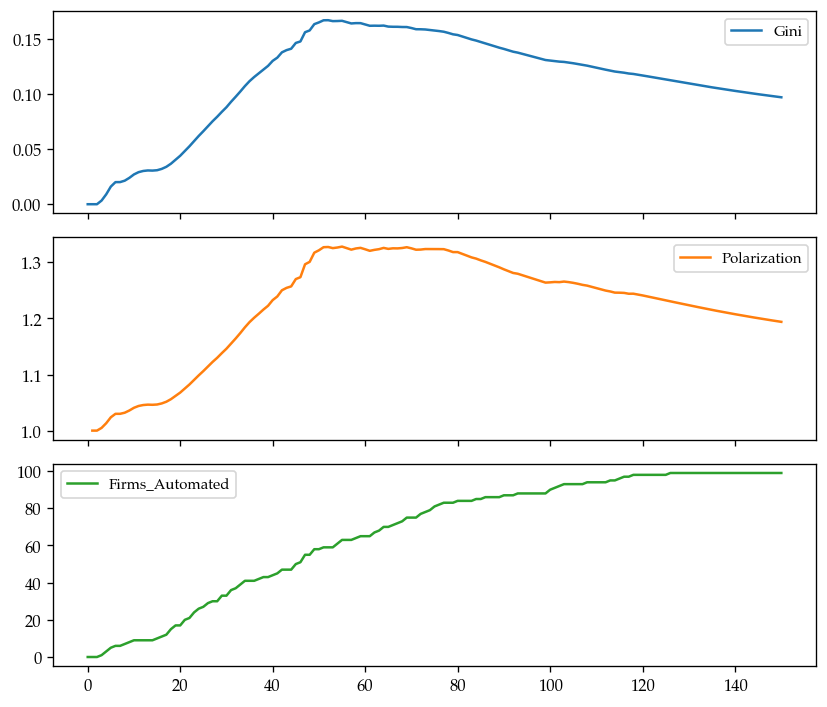

In [4]:
# Single-run sanity check on the Axelrod specification
smoke = AutomationModel(seed=SEED, gamma=GAMMA, buffer_months=3, patience_decay=0.05)
for _ in range(N_STEPS):
    smoke.step()

df_smoke = smoke.datacollector.get_model_vars_dataframe()
df_smoke[["Gini", "Polarization", "Firms_Automated"]].plot(subplots=True, figsize=(7, 6))
plt.tight_layout()
plt.show()


## Part I: Statistical Model Checking 

MultiVeStA estimates the expected value of an observable and keeps adding independent replications until the confidence interval is tighter than a user-set threshold, rather than fixing the number of runs by hand. Two elements are required:

1. a thin **wrapper** exposing the three methods a MultiVeStA simulator must provide: reinitialise with a given seed (`set_simulator_for_new_simulation`), advance one step (`perform_one_step`), and read an observable (`eval`);
2. an **adaptive transient driver** that, for a finite horizon, estimates $E[\text{obs}](t)$ at every step and stops once the half-width of the $t$-Student confidence interval falls below the target for all steps and all observables.

For the model's transient, finite-horizon dynamics (one-way AI adoption, a single retraining decision) this transient estimator is the appropriate MultiVeStA mode; steady-state estimation would be ill-posed on an absorbing process. The analysis below is run on the **main specification** (`buffer_months = 3`, `patience_decay = 0.05`).

In [5]:
# MultiVeStA wrapper around AutomationModel (does not modify the class)
class SMCAutomationModel:
    """Adapter exposing the interface a MultiVeStA-style driver expects.

    The model kwargs are stored and reused at every reinitialisation, so a
    counterfactual is a matter of instantiating the adapter with different
    parameters. Observations coincide with the DataCollector's model_reporters,
    keeping a single source of truth for the metrics.
    """

    def __init__(self, **model_kwargs):
        self.model_kwargs = model_kwargs
        self._m = None

    def set_simulator_for_new_simulation(self, seed):
        kwargs = dict(self.model_kwargs)
        kwargs["seed"] = seed
        self._m = AutomationModel(**kwargs)          # firms/workers rebuilt for the new run

    def perform_one_step(self):
        self._m.step()

    def get_time(self):
        return self._m.current_step

    def eval(self, obs):
        """Read an observable from the model_reporters (resolves @property metrics)."""
        reporters = self._m.datacollector.model_reporters
        if obs not in reporters:
            raise KeyError(f"Observation '{obs}' not found. Available: {sorted(reporters)}")
        val = reporters[obs](self._m)
        return float(val() if callable(val) else val)

    def observations(self):
        return sorted(self._m.datacollector.model_reporters) if self._m \
            else "call set_simulator_for_new_simulation(seed) first"


In [6]:
def smc_transient(model_factory, observations, n_steps, alpha=0.05,
                  targets=None,            # {obs: (delta, is_relative)}; per-observable target
                  default=(0.10, True),    # fallback for observables not listed in `targets`
                  n_init=30, n_batch=20, max_runs=2000, seed_offset=0, verbose=True):
    """Transient estimation with CI-based adaptive stopping, per-observable target.

    Each observable can be checked with its own tolerance and mode: a RELATIVE
    target (half-width <= delta * |mean|) suits quantities bounded away from zero
    (e.g. Polarization ~ 1); an ABSOLUTE target (half-width <= delta) suits bounded
    indices that pass through zero (e.g. Gini in [0,1] at the start of the horizon,
    where a relative target is ill-posed). Stops when ALL targets are met.
    """
    T = n_steps + 1
    raw = {o: [] for o in observations}
    tgt = {o: (targets or {}).get(o, default) for o in observations}   # resolve per-obs target

    def run_one(seed):
        sim = model_factory(); sim.set_simulator_for_new_simulation(seed)
        traj = {o: np.full(T, np.nan) for o in observations}
        for o in observations: traj[o][0] = sim.eval(o)               # t = 0 (initial state)
        for t in range(1, T):
            sim.perform_one_step()
            for o in observations: traj[o][t] = sim.eval(o)
        return traj

    n_runs = 0
    def add_runs(k):
        nonlocal n_runs
        for j in range(k):
            traj = run_one(seed_offset + n_runs + j)
            for o in observations: raw[o].append(traj[o])
        n_runs += k

    def stats_and_met():
        tcrit = stats.t.ppf(1 - alpha / 2, df=max(n_runs - 1, 1))
        means, halfs, all_met = {}, {}, True
        for o in observations:
            arr = np.array(raw[o]); mu = np.nanmean(arr, 0); sd = np.nanstd(arr, 0, ddof=1)
            hw = tcrit * sd / np.sqrt(n_runs); means[o], halfs[o] = mu, hw
            delta, is_rel = tgt[o]
            crit = hw / np.maximum(np.abs(mu), 1e-9) if is_rel else hw   # relative vs absolute
            if np.nanmax(crit) > delta:
                all_met = False
        return means, halfs, all_met

    add_runs(n_init); means, halfs, met = stats_and_met()
    while (not met) and n_runs < max_runs:
        add_runs(n_batch); means, halfs, met = stats_and_met()
    if verbose:
        print(f"Stop: {n_runs} runs -- targets {'reached' if met else 'MAX RUNS reached'}.")
    return {"steps": np.arange(T), "mean": means, "halfwidth": halfs, "n_runs": n_runs}


### Transient estimation on the main specification

Two observables are estimated at the 95% confidence level. **Polarization** oscillates around 1, so a *relative* 5% target is well-conditioned. **Gini** starts from 0 and rises, so a relative target would never be met at the early near-zero steps; it is therefore estimated to an *absolute* half-width of 0.01 (on a 0-1 index). The driver reports how many replications each target required.

In [7]:

# Main specification: buffer_months = 3, patience_decay = 0.05, gamma = 0.032.
def make_model():
    return SMCAutomationModel(gamma=GAMMA, buffer_months=3, patience_decay=0.05)

OBS = ["Polarization", "Gini"]

TARGETS = {"Polarization": (0.05, True), "Gini": (0.01, False)}

res = smc_transient(make_model, OBS, n_steps=N_STEPS, alpha=0.05,
    targets=TARGETS, n_init=30, n_batch=20, max_runs=1000)

N_RUNS = res["n_runs"]                        # <-- feeds the Monte Carlo in Part II
print("\nReplications chosen automatically:", N_RUNS)

# Diagnostic: binding step / observable
for obs in OBS:
    _, is_rel = TARGETS[obs]
    crit = (res["halfwidth"][obs] / np.maximum(np.abs(res["mean"][obs]), 1e-9)
            if is_rel else res["halfwidth"][obs])
    ws = int(np.nanargmax(crit[1:]) + 1)
    print(f"{obs:13s} worst step = {ws:3d}  half-width ({'rel' if is_rel else 'abs'}) = "
          f"{crit[ws]:.4f}  (mean = {res['mean'][obs][ws]:.4f})")


Stop: 50 runs -- targets reached.

Replications chosen automatically: 50
Polarization  worst step =  42  half-width (rel) = 0.0148  (mean = 1.3014)
Gini          worst step =  30  half-width (abs) = 0.0082  (mean = 0.1241)


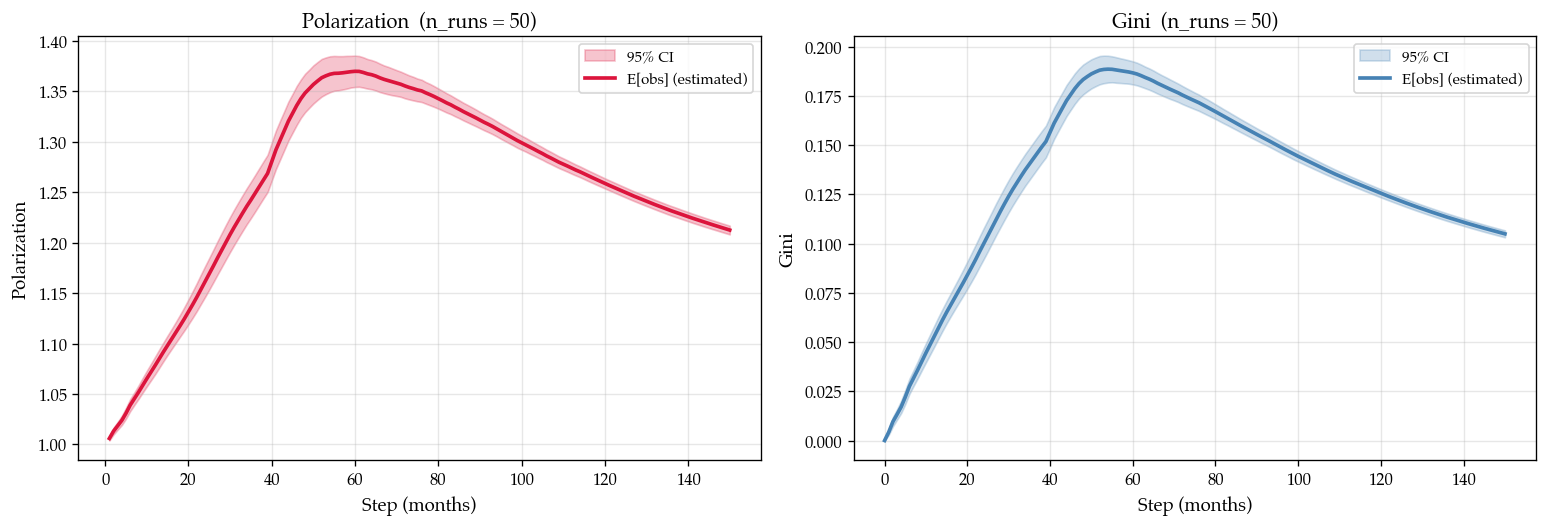

In [8]:
# Estimated trajectories with 95% confidence bands
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, obs, c in zip(axes, OBS, ["crimson", "steelblue"]):
    mu, hw = res["mean"][obs], res["halfwidth"][obs]
    ax.fill_between(res["steps"], mu - hw, mu + hw, alpha=0.25, color=c, label="95% CI")
    ax.plot(res["steps"], mu, color=c, lw=2.2, label="E[obs] (estimated)")
    ax.set_title(f"{obs}  (n_runs = {res['n_runs']})")
    ax.set_xlabel("Step (months)"); ax.set_ylabel(obs)
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()



## Part II: Monte Carlo analysis over four configurations

The model is replicated over N_RUNS replications, chosen by the SMC in Part I to meet the 95% CI target, under four configurations, crossing the precautionary buffer with the hiring-patience decay:

| Configuration | `buffer_months` | `patience_decay` | Role |
|---|---|---|---|
| 1 | 3 | 0.05 | **Main specification** |
| 2 | 3 | 0.02 | Robustness (slower reservation erosion) |
| 3 | 0 | 0.05 | Robustness (no precautionary buffer) |
| 4 | 0 | 0.02 | Robustness (both) |

`buffer_months` shifts the retraining threshold $\Theta$ (conditional on holding savings equivalent to 3 months of salary); `patience_decay` governs how fast a firm's skill reservation erodes when hiring, hence how readily unreskilled workers are absorbed. The four runs are a sensitivity grid: agreement in the qualitative pattern across them is a robustness result, not a weakness.

Averaging over seeds smooths the stochastic adoption timing and the random firing/hiring draws. For each configuration three figures are produced: (1) inequality, polarization, unemployment, and savings/wages by seniority; (2) reskilling among the displaced and AI diffusion; (3) the final-step cross-seed distributions of the emergent outcomes as histograms. Mean trajectories are shown with 5th-95th percentile bands.

In [9]:
# Monte Carlo engine and figures (defined once, reused for every configuration)

TRACK = ["Gini", "Polarization", "Gini_Savings_Junior", "N_Unemployed",
         "Mean_Savings_Junior", "Mean_Savings_Senior",
         "Mean_Wage_Junior", "Mean_Wage_Senior",
         "Frac_Reskilled_AmongDisplaced", "Firms_Automated"]


def run_mc(buffer_months, patience_decay, n_runs=None, n_steps=N_STEPS, gamma=GAMMA):
    """Replicate the Axelrod model over seeds 0..n_runs-1; return per-step summary
    statistics, the raw (n_runs x steps) arrays, and the pooled final firm revenues."""
    
    if n_runs is None:
        n_runs = N_RUNS          # sample size chosen by the SMC in Part I
    res = {v: np.full((n_runs, n_steps + 1), np.nan) for v in TRACK}
    firm_rev = []
    for run in range(n_runs):
        m = AutomationModel(seed=run, gamma=gamma,
                            buffer_months=buffer_months, patience_decay=patience_decay)
        for _ in range(n_steps):
            m.step()
        d = m.datacollector.get_model_vars_dataframe()
        for v in TRACK:
            res[v][run] = d[v].values
        firm_rev.extend(f.firm_revenue for f in m.firms_pool)
    s = {v: {"mean": np.nanmean(res[v], 0),
             "p05":  np.nanpercentile(res[v], 5, 0),
             "p95":  np.nanpercentile(res[v], 95, 0)} for v in TRACK}
    return s, res, np.array(firm_rev)


def plot_mc(s, res, firm_rev, label):
    """Three figures for one configuration, plus a compact final-step table."""
    steps = np.arange(res["Gini"].shape[1])

    def band(a, v, c, ttl, yl):
        a.fill_between(steps, s[v]["p05"], s[v]["p95"], alpha=0.20, color=c, label="5th-95th pct")
        a.plot(steps, s[v]["mean"], color=c, lw=2.2, label="Mean")
        a.set_title(ttl); a.set_xlabel("Step (months)"); a.set_ylabel(yl)
        a.grid(alpha=0.3); a.legend(fontsize=8)

    def pair(a, vj, vs, ttl, yl):
        for v, c, lab in [(vj, "crimson", "Junior"), (vs, "navy", "Senior")]:
            a.fill_between(steps, s[v]["p05"], s[v]["p95"], alpha=0.15, color=c)
            a.plot(steps, s[v]["mean"], color=c, lw=2.2, label=lab)
        a.set_title(ttl); a.set_xlabel("Step (months)"); a.set_ylabel(yl)
        a.grid(alpha=0.3); a.legend(fontsize=8)

    # FIGURE 1 -- inequality, polarization, unemployment, savings & wages by seniority
    fig, ax = plt.subplots(3, 2, figsize=(13, 13))
    band(ax[0, 0], "Gini", "steelblue",
         f"Gini -- all workers (final mean = {s['Gini']['mean'][-1]:.2f})", "Gini")
    band(ax[0, 1], "Polarization", "crimson", "Polarization index (Senior/Junior savings)", "ratio")
    band(ax[1, 0], "Gini_Savings_Junior", "purple",
         f"Gini -- Juniors only (final mean = {s['Gini_Savings_Junior']['mean'][-1]:.2f})", "Gini")
    band(ax[1, 1], "N_Unemployed", "darkorange", "Unemployment over time", "# unemployed")
    pair(ax[2, 0], "Mean_Savings_Junior", "Mean_Savings_Senior",
         "Savings divergence by seniority", "mean savings (all workers)")
    pair(ax[2, 1], "Mean_Wage_Junior", "Mean_Wage_Senior",
         "Wage divergence by seniority", "mean wage (employed)")
    fig.suptitle(f"Figure 1 -- {label}", fontsize=14, y=1.002)
    plt.tight_layout(); plt.show()

    # FIGURE 2 -- reskilling among displaced vs AI diffusion
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
    band(ax[0], "Frac_Reskilled_AmongDisplaced", "teal",
         f"Reskilled fraction among ever-displaced (final = {s['Frac_Reskilled_AmongDisplaced']['mean'][-1]:.2f})",
         "fraction")
    ax[0].set_ylim(0, 1)
    band(ax[1], "Firms_Automated", "darkgreen", "AI adoption (firms automated)", "# firms")
    fig.suptitle(f"Figure 2 -- {label}", fontsize=13)
    plt.tight_layout(); plt.show()

    # FIGURE 3 -- final-step (t = 150) cross-seed distributions as histograms
    hist = [("Gini", "steelblue"), ("Polarization", "crimson"),
            ("Gini_Savings_Junior", "purple"),
            ("Frac_Reskilled_AmongDisplaced", "teal"), ("N_Unemployed", "darkorange")]
    fig, ax = plt.subplots(2, 3, figsize=(15, 8)); axf = ax.flatten()
    for k, (v, c) in enumerate(hist):
        fv = res[v][:, -1]
        axf[k].hist(fv, bins=20, color=c, alpha=0.75, edgecolor="white")
        axf[k].axvline(np.nanmedian(fv), ls="--", color="black",
                       label=f"median = {np.nanmedian(fv):.2f}")
        axf[k].set_title(v); axf[k].set_ylabel("# seeds")
        axf[k].grid(alpha=0.3); axf[k].legend(fontsize=8)
    axf[5].hist(firm_rev, bins=30, color="saddlebrown", alpha=0.75, edgecolor="white")
    axf[5].axvline(np.median(firm_rev), ls="--", color="black",
                   label=f"median = {np.median(firm_rev):.0f}")
    axf[5].set_title("Firm revenue (pooled over seeds)"); axf[5].set_ylabel("# firms")
    axf[5].grid(alpha=0.3); axf[5].legend(fontsize=8)
    fig.suptitle(f"Figure 3 -- final-step distributions -- {label}", fontsize=13)
    plt.tight_layout(); plt.show()

    # Compact final-step summary table
    tbl = pd.DataFrame({
        "Variable": TRACK,
        "Mean": [round(np.nanmean(res[v][:, -1]), 4) for v in TRACK],
        "p05":  [round(np.nanpercentile(res[v][:, -1], 5), 4) for v in TRACK],
        "p95":  [round(np.nanpercentile(res[v][:, -1], 95), 4) for v in TRACK],
    })
    print(f"FINAL-STEP SUMMARY (step {N_STEPS}, {N_RUNS} seeds) -- {label}")
    print(tbl.to_string(index=False))


### Running the four configurations

The main specification is reported first, followed by the three robustness variants. Each block prints the three figures and the final-step summary table for that configuration. (Runtime scales with `N_RUNS`; the full grid is four batches of N_RUNS replications.)

Main spec (buffer_months=3, patience_decay=0.05)


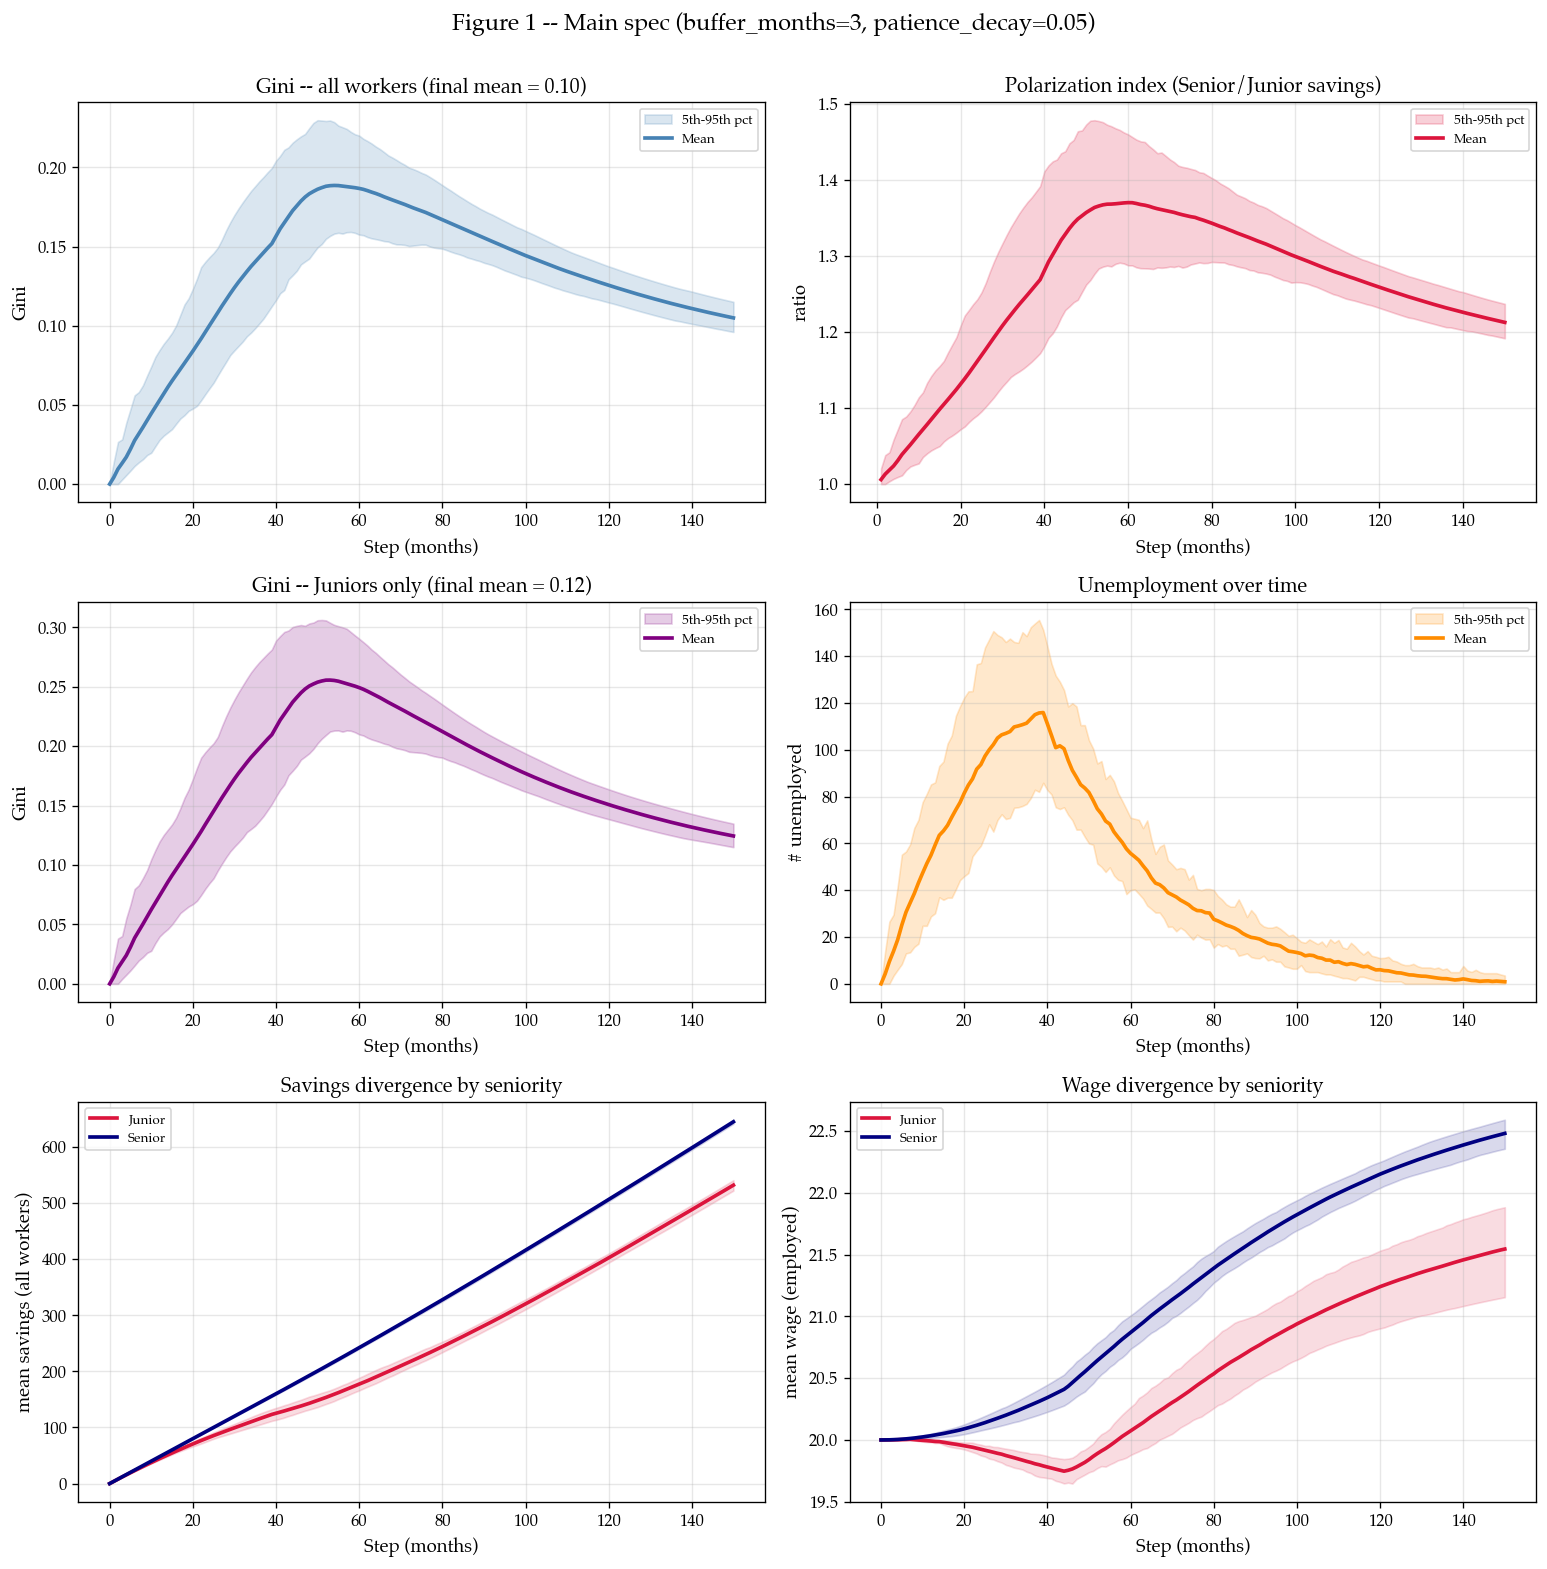

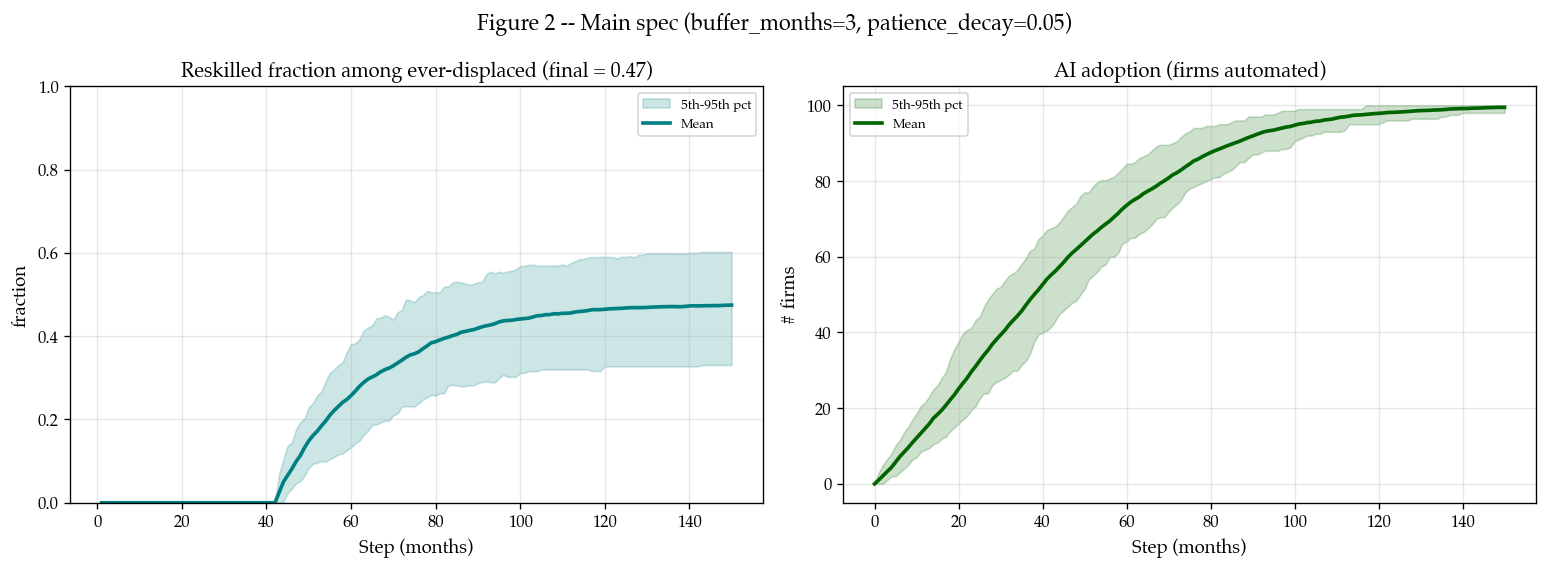

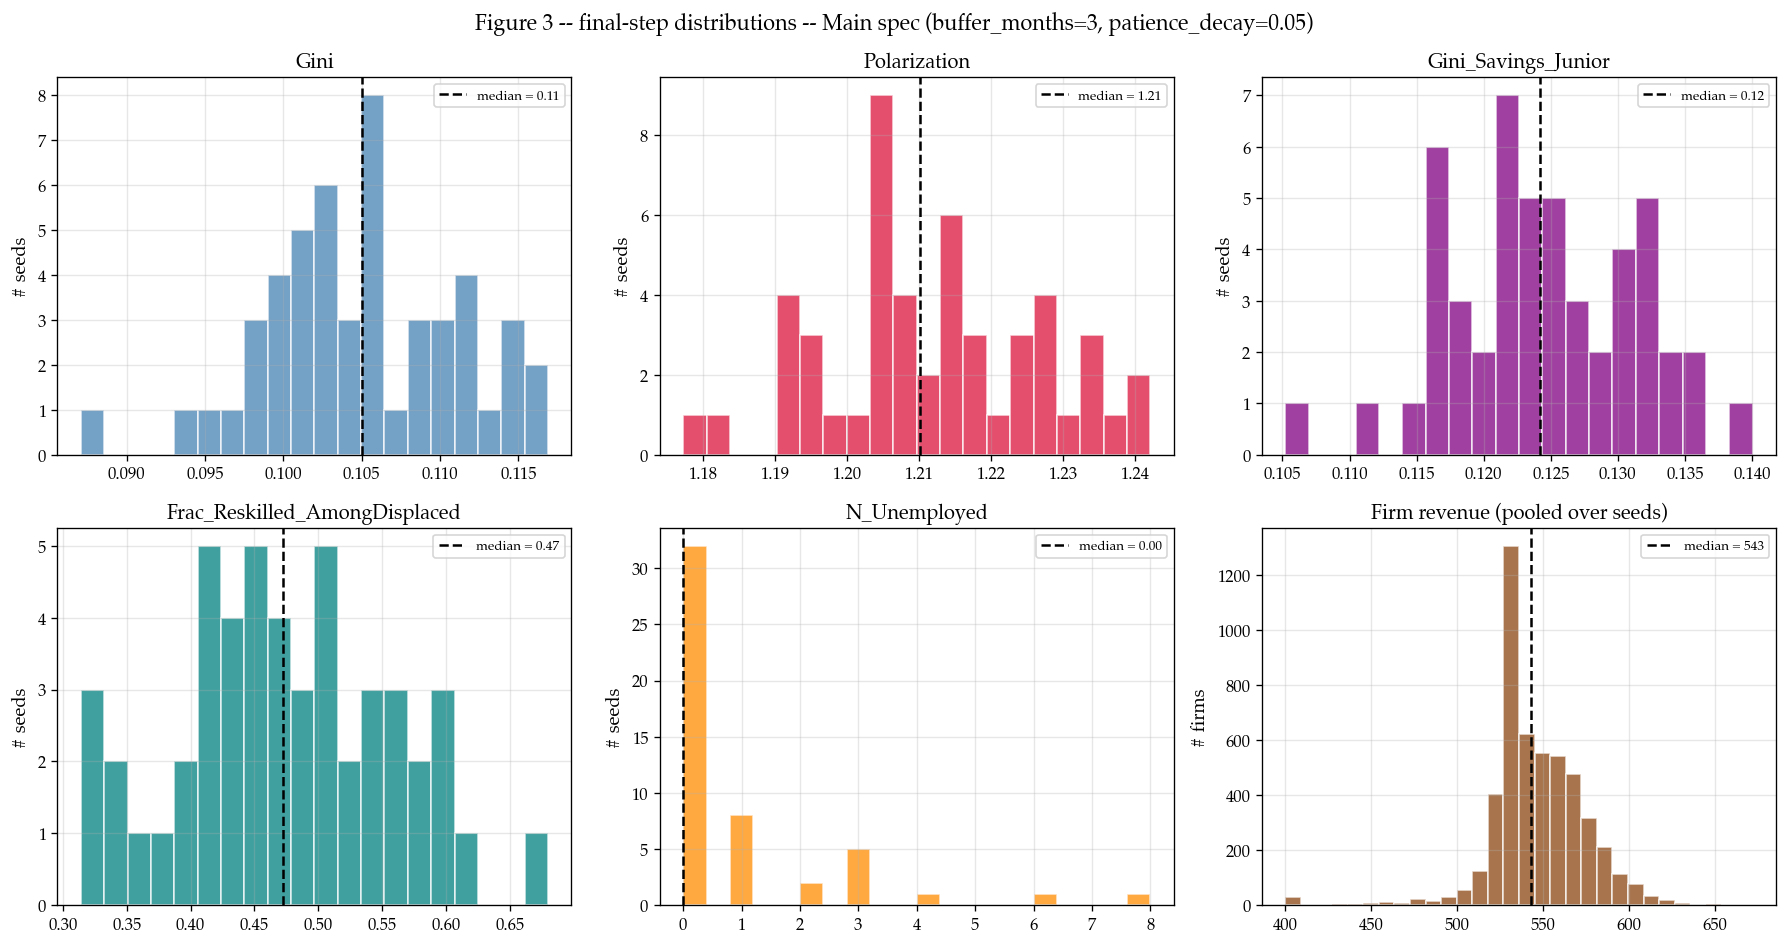

FINAL-STEP SUMMARY (step 150, 50 seeds) -- Main spec (buffer_months=3, patience_decay=0.05)
                     Variable     Mean      p05      p95
                         Gini   0.1050   0.0961   0.1151
                 Polarization   1.2124   1.1915   1.2367
          Gini_Savings_Junior   0.1244   0.1150   0.1348
                 N_Unemployed   0.9000   0.0000   3.5500
          Mean_Savings_Junior 532.1401 522.4200 540.9744
          Mean_Savings_Senior 645.0979 641.5798 648.7810
             Mean_Wage_Junior  21.5461  21.1560  21.8848
             Mean_Wage_Senior  22.4827  22.3581  22.5935
Frac_Reskilled_AmongDisplaced   0.4748   0.3307   0.6024
              Firms_Automated  99.4600  98.0000 100.0000
buffer_months=3, patience_decay=0.02


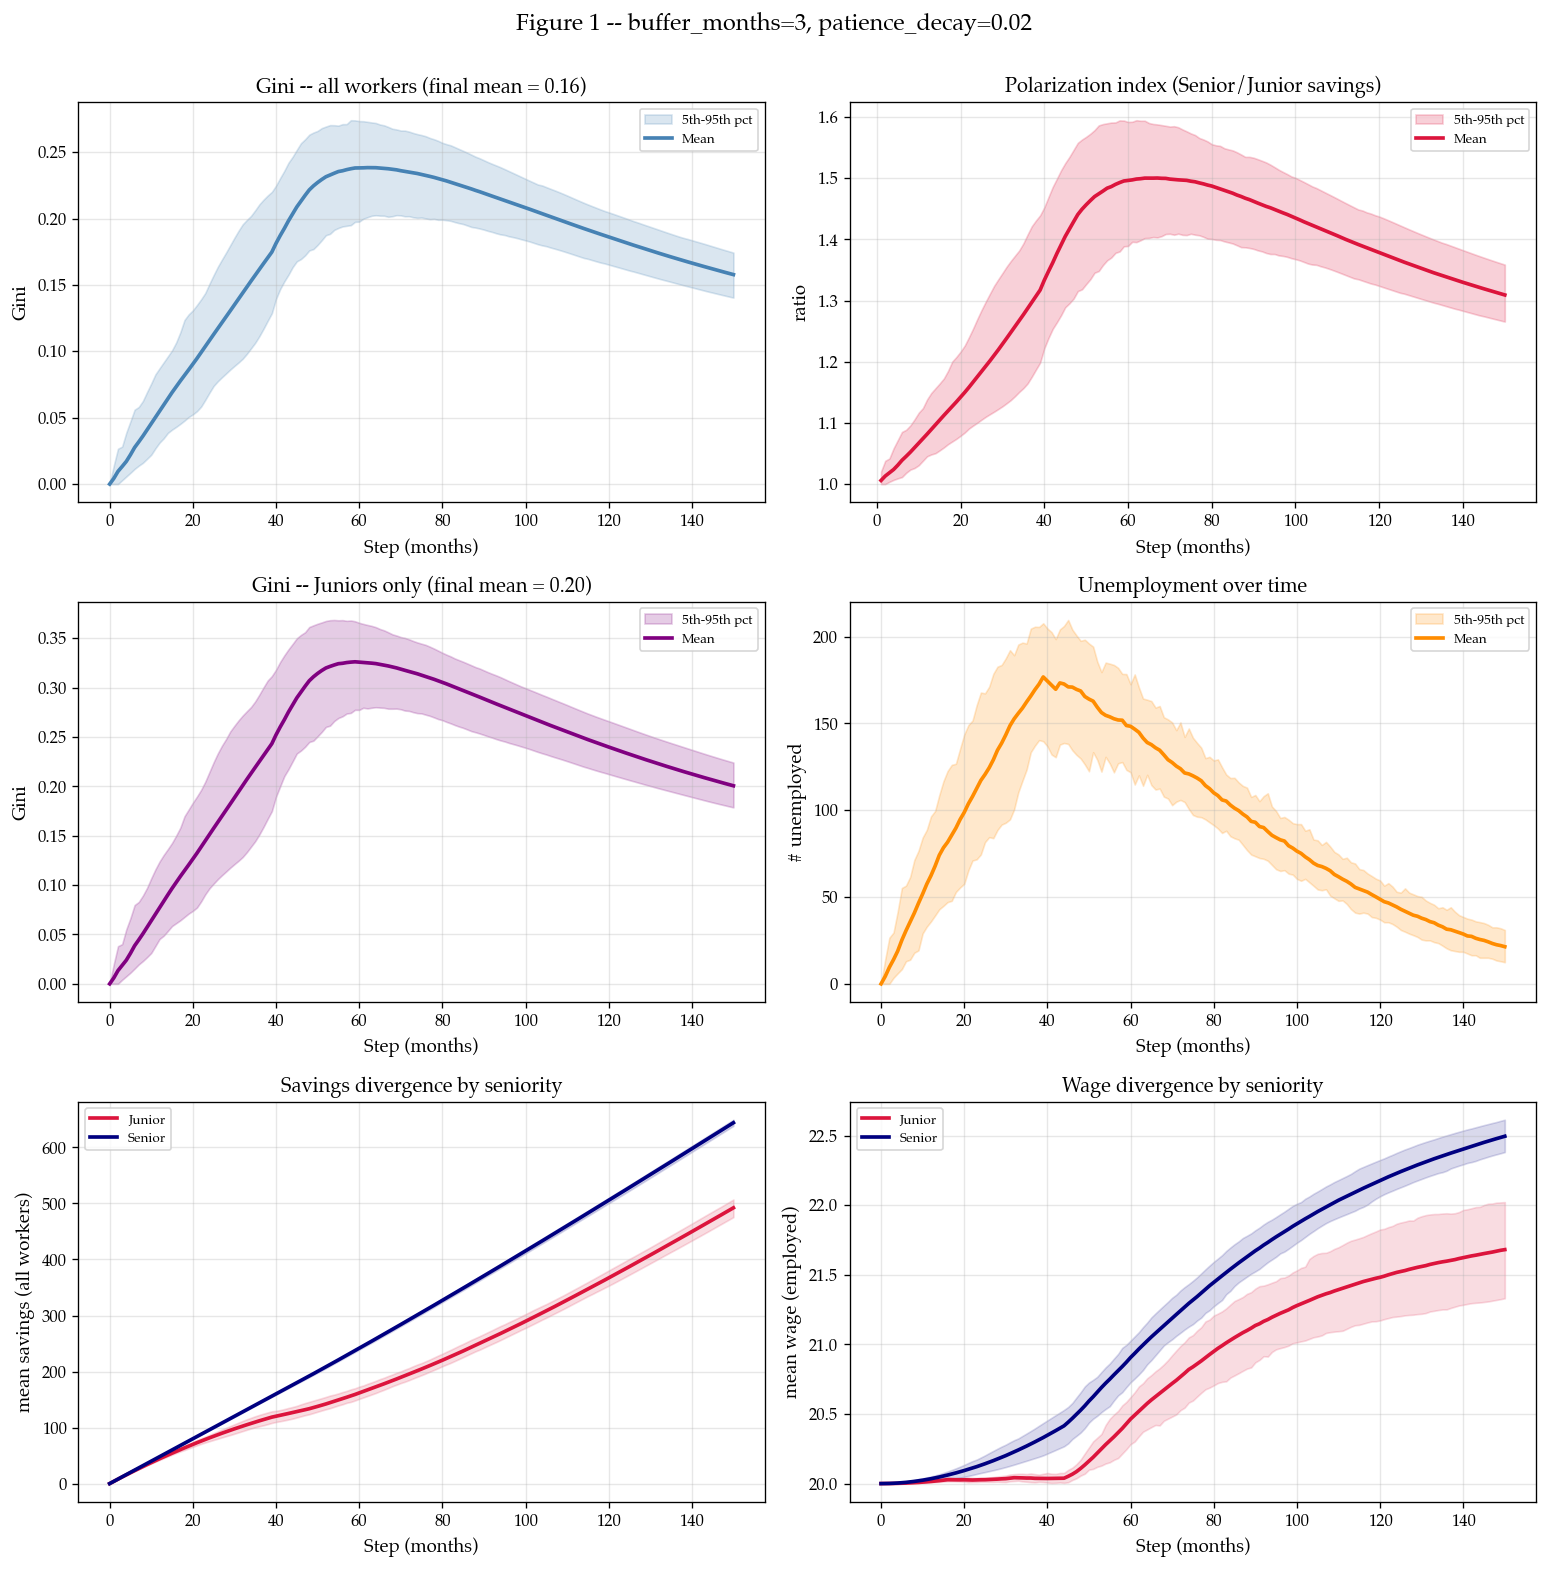

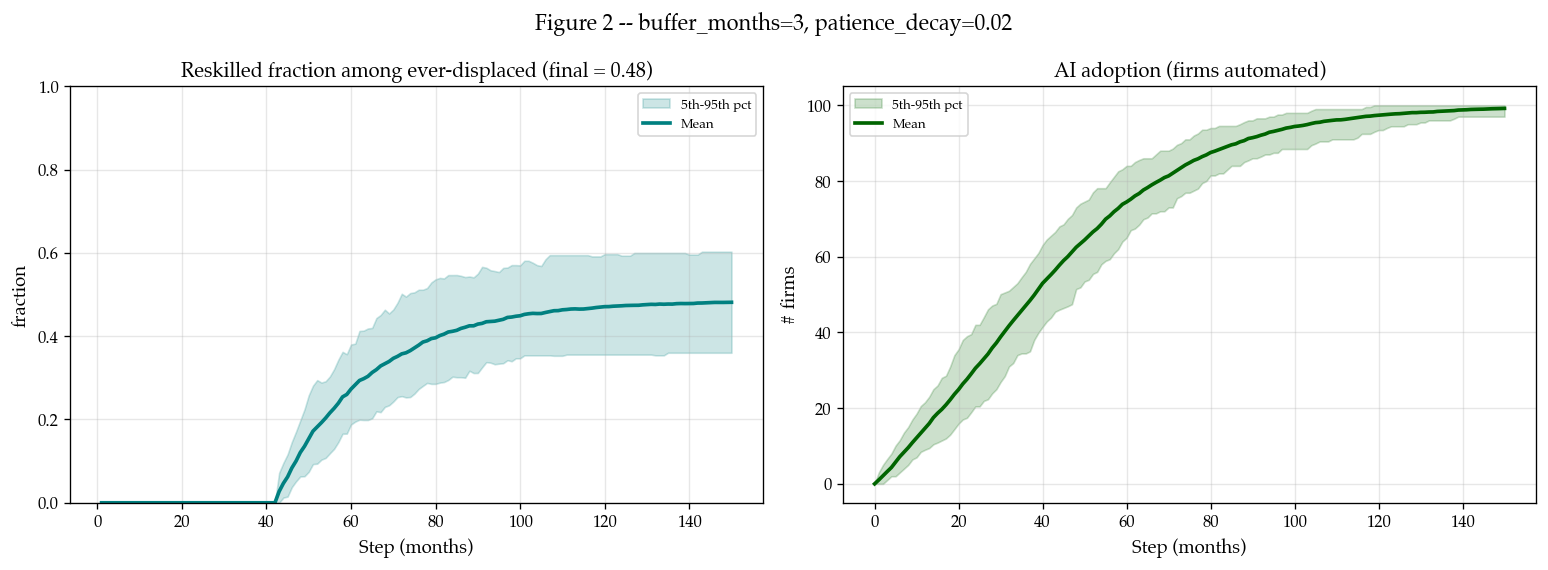

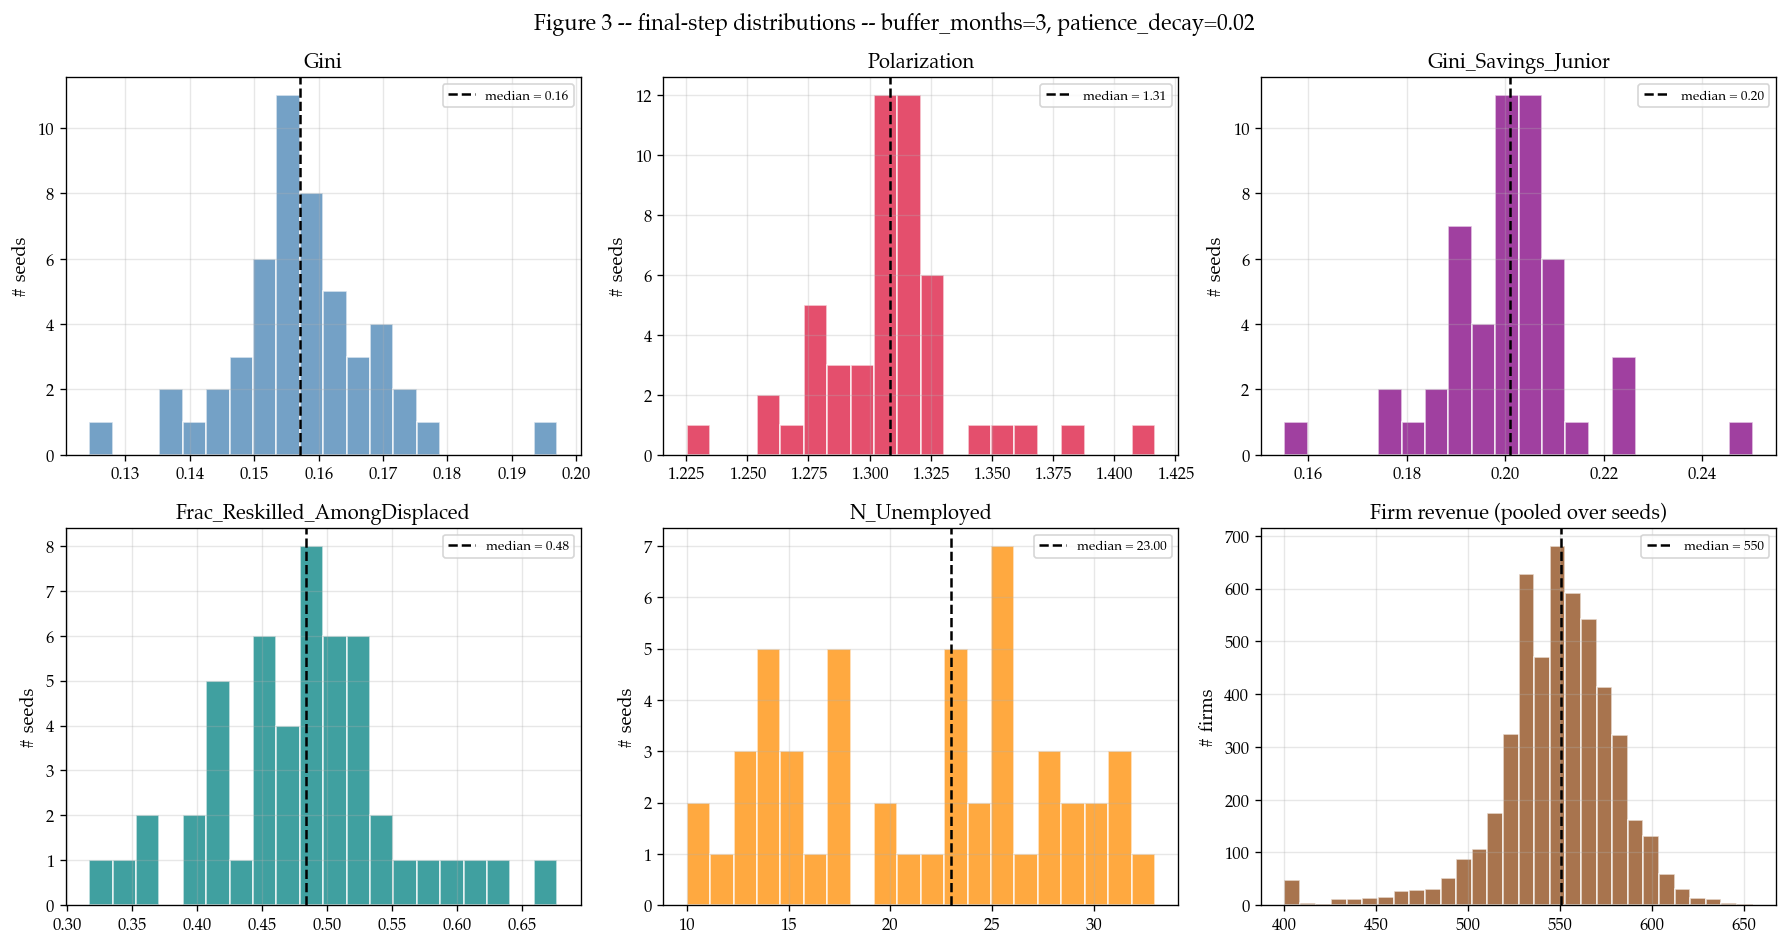

FINAL-STEP SUMMARY (step 150, 50 seeds) -- buffer_months=3, patience_decay=0.02
                     Variable     Mean      p05      p95
                         Gini   0.1578   0.1404   0.1743
                 Polarization   1.3092   1.2657   1.3588
          Gini_Savings_Junior   0.2006   0.1787   0.2241
                 N_Unemployed  21.3800  12.4500  31.0000
          Mean_Savings_Junior 492.2499 475.6062 507.0861
          Mean_Savings_Senior 644.1312 638.5387 649.4999
             Mean_Wage_Junior  21.6807  21.3313  22.0223
             Mean_Wage_Senior  22.4954  22.3816  22.6141
Frac_Reskilled_AmongDisplaced   0.4815   0.3603   0.6029
              Firms_Automated  99.1800  97.0000 100.0000
buffer_months=0, patience_decay=0.05


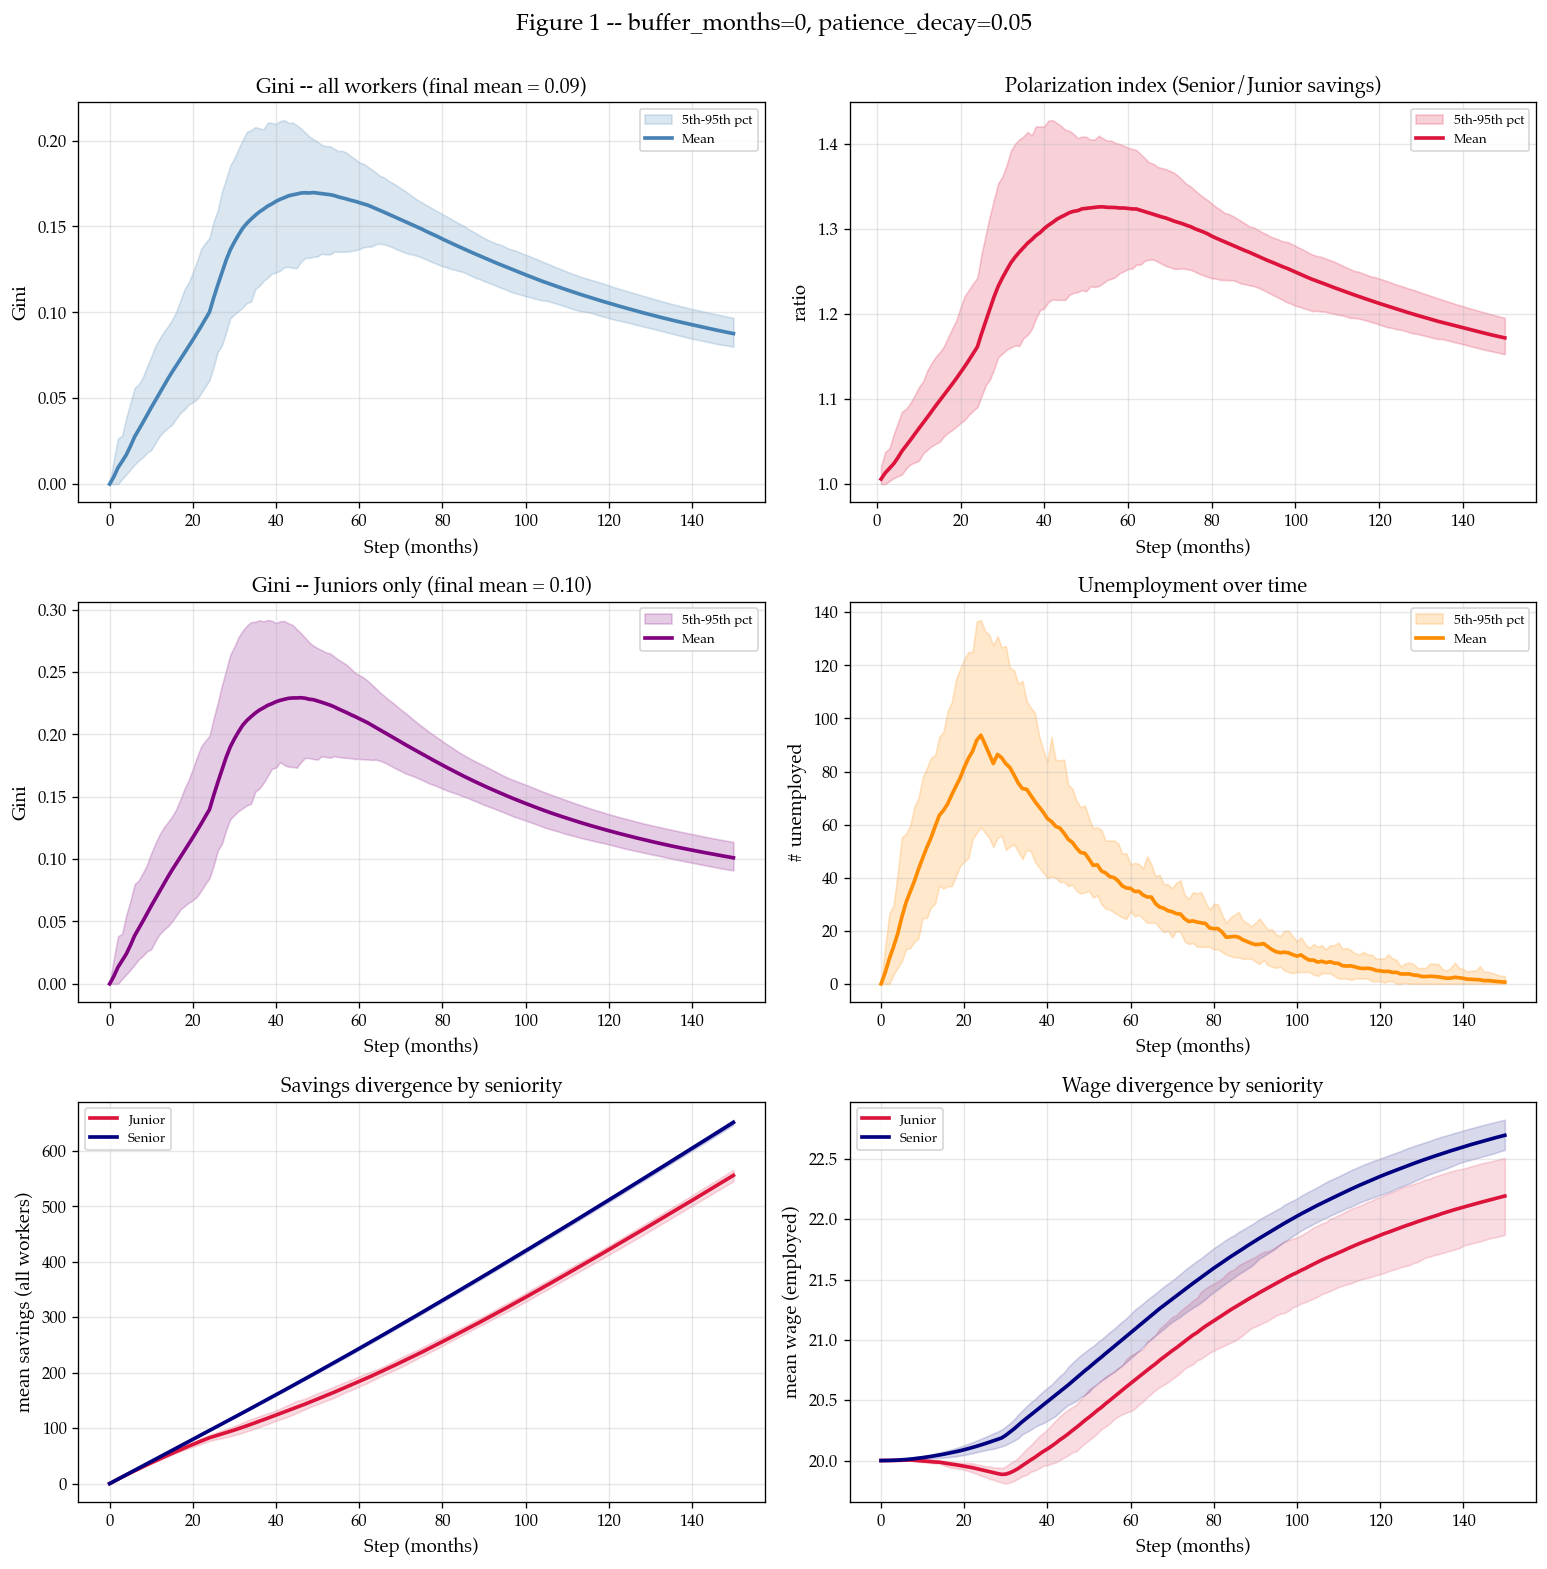

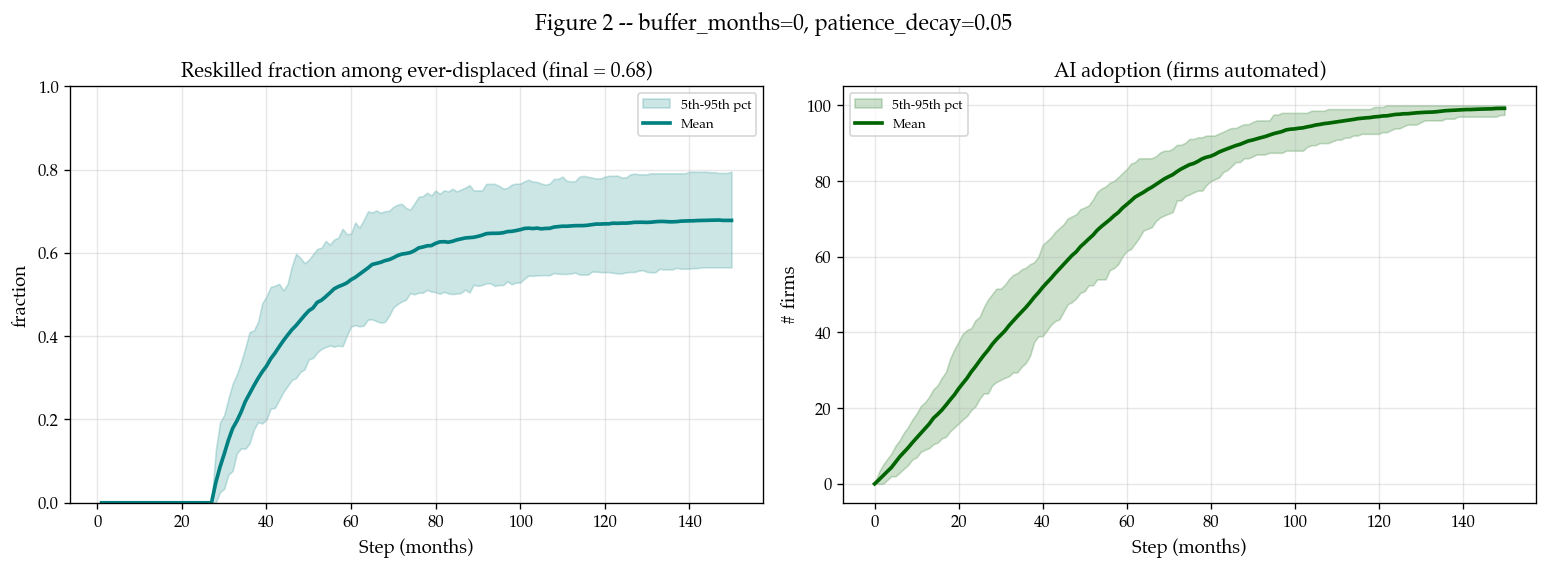

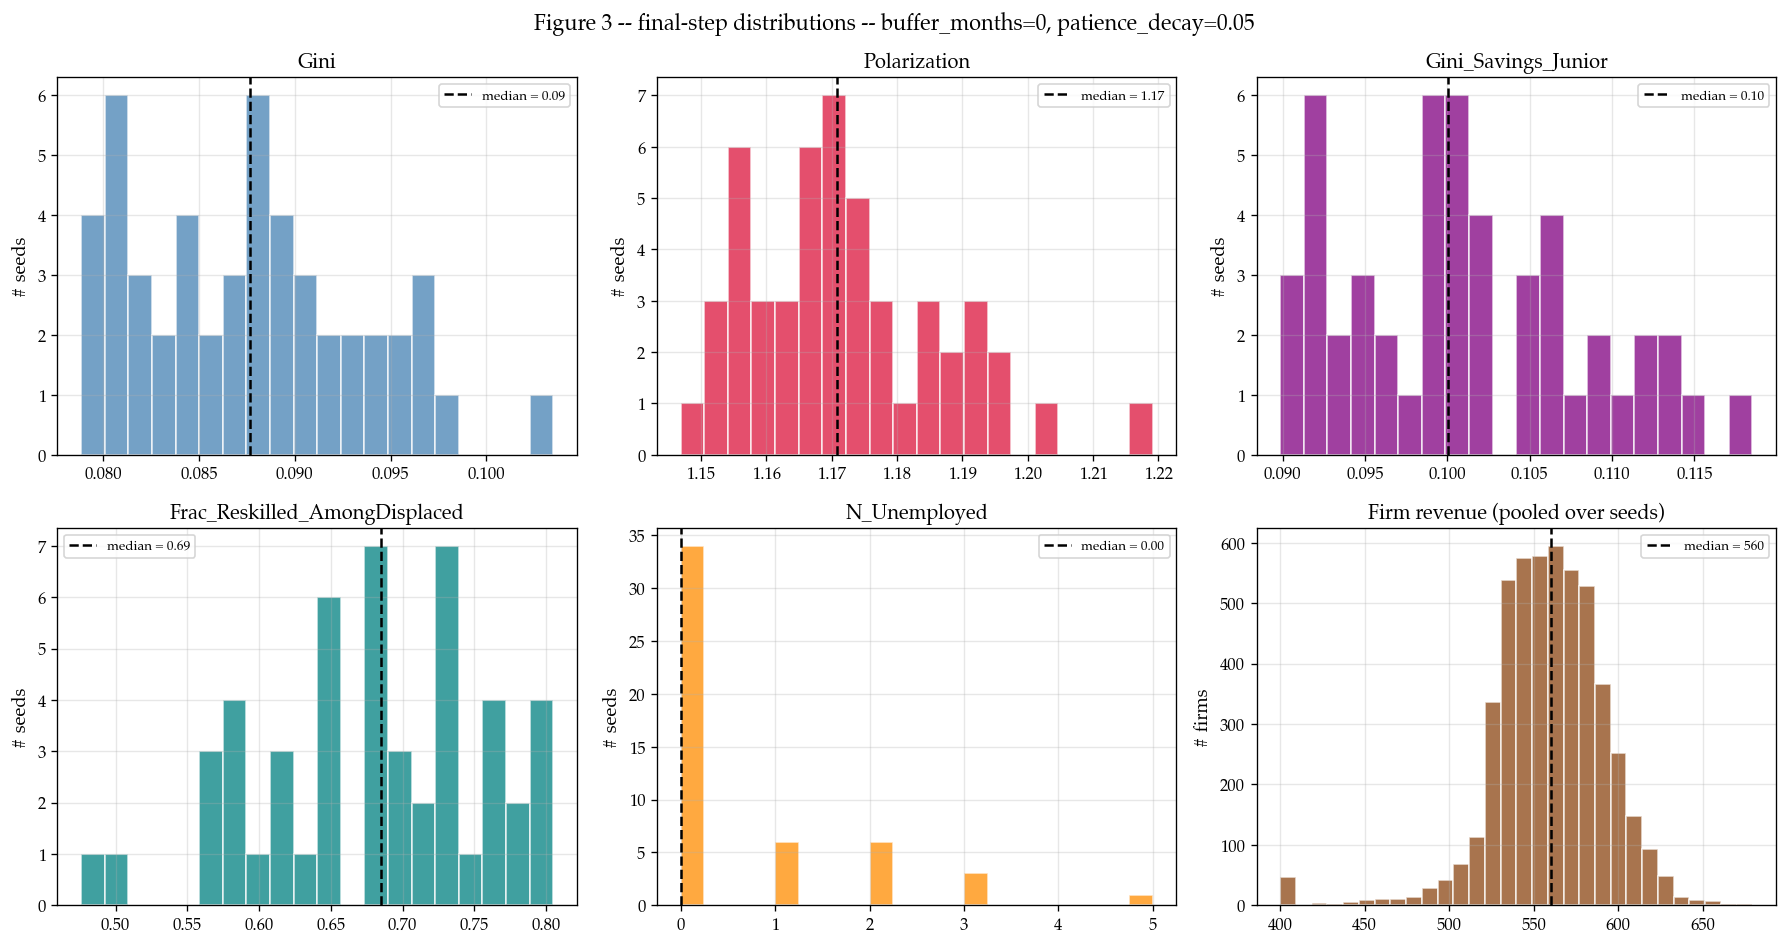

FINAL-STEP SUMMARY (step 150, 50 seeds) -- buffer_months=0, patience_decay=0.05
                     Variable     Mean      p05      p95
                         Gini   0.0876   0.0800   0.0968
                 Polarization   1.1721   1.1529   1.1956
          Gini_Savings_Junior   0.1011   0.0910   0.1137
                 N_Unemployed   0.6400   0.0000   3.0000
          Mean_Savings_Junior 556.1502 545.6018 565.9606
          Mean_Savings_Senior 651.7570 647.3836 656.5427
             Mean_Wage_Junior  22.1925  21.8694  22.5083
             Mean_Wage_Senior  22.6959  22.5741  22.8246
Frac_Reskilled_AmongDisplaced   0.6781   0.5654   0.7952
              Firms_Automated  99.2000  97.4500 100.0000
buffer_months=0, patience_decay=0.02


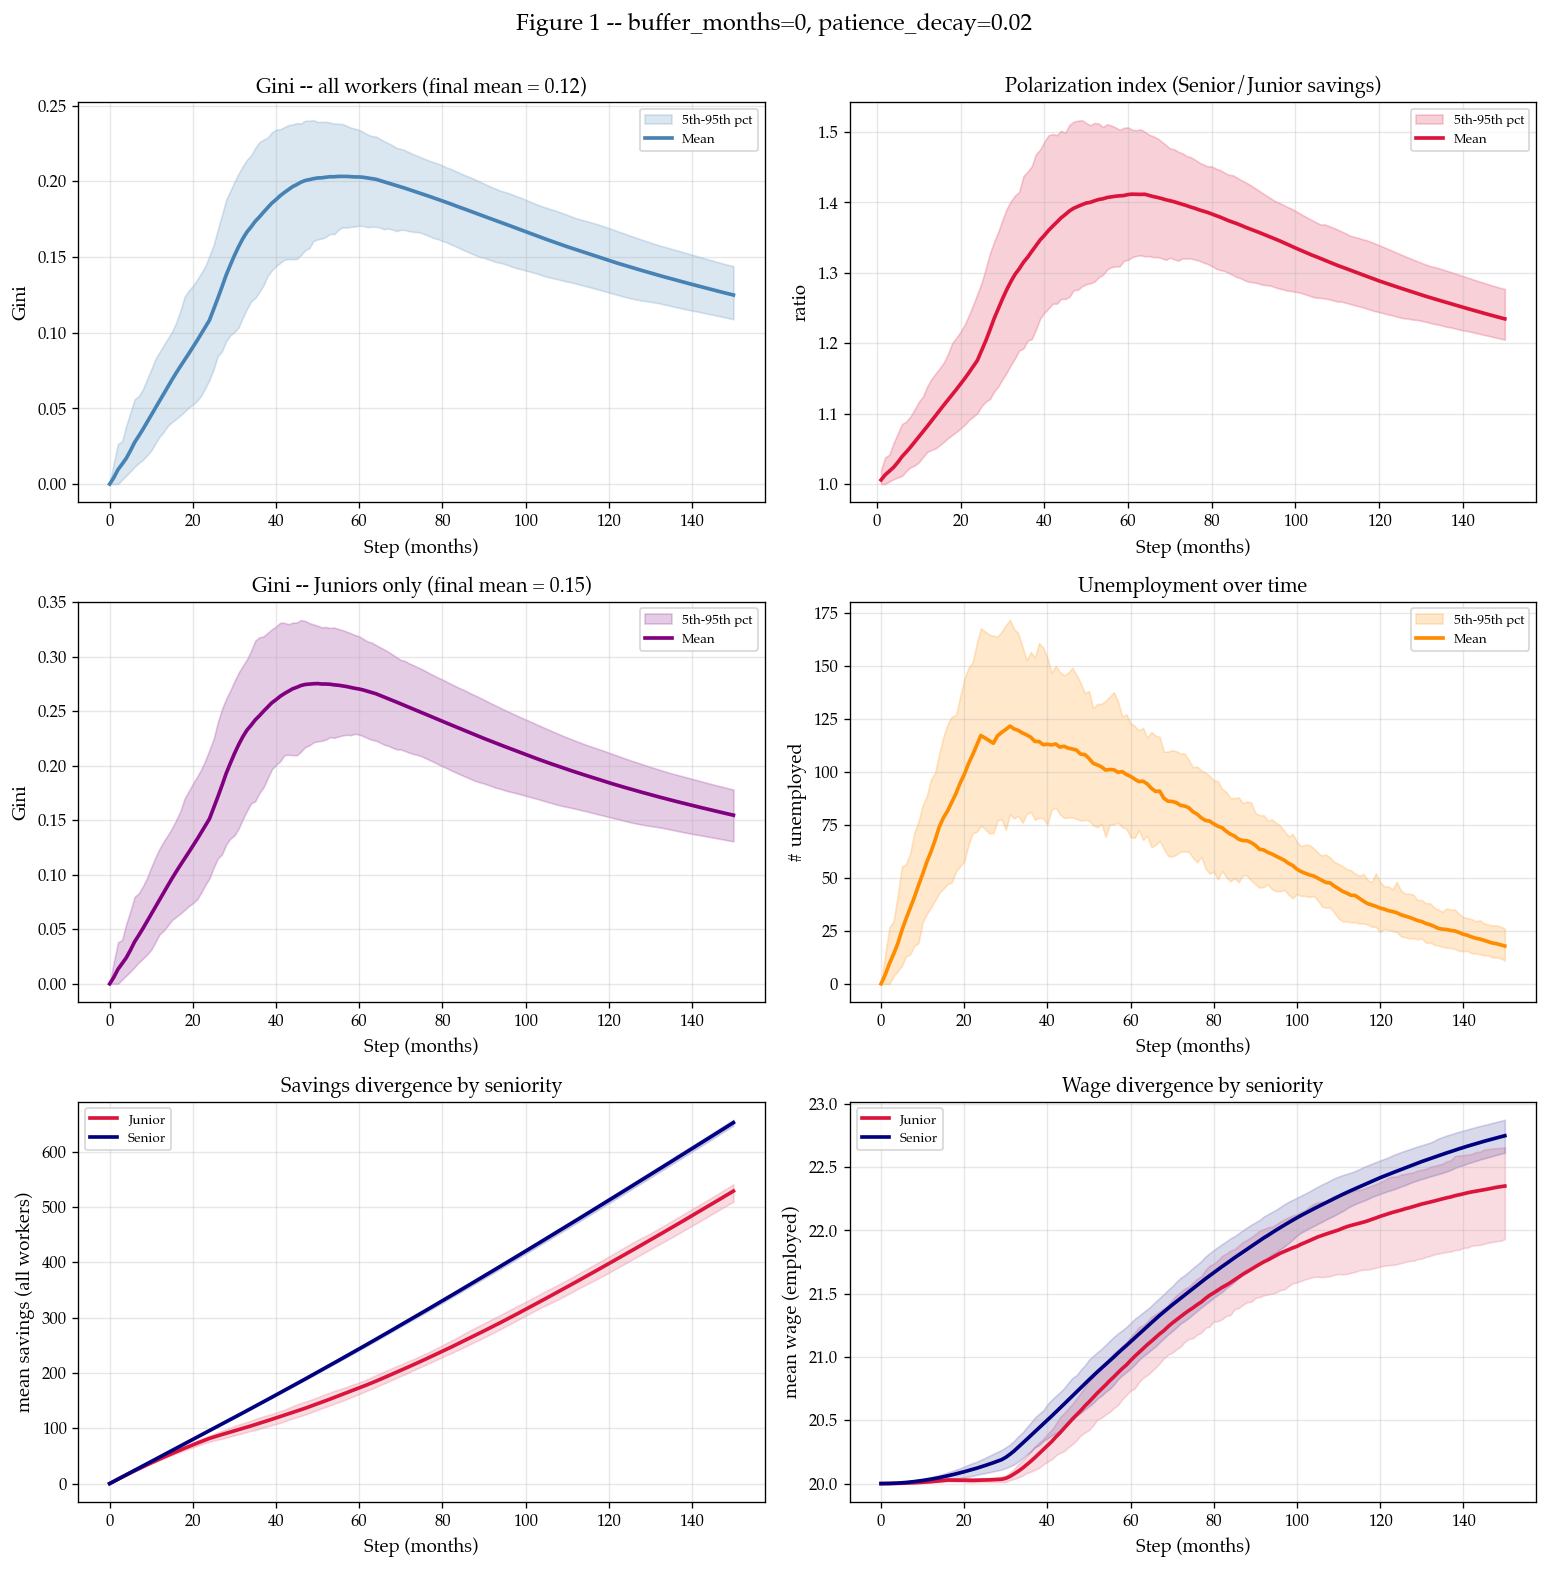

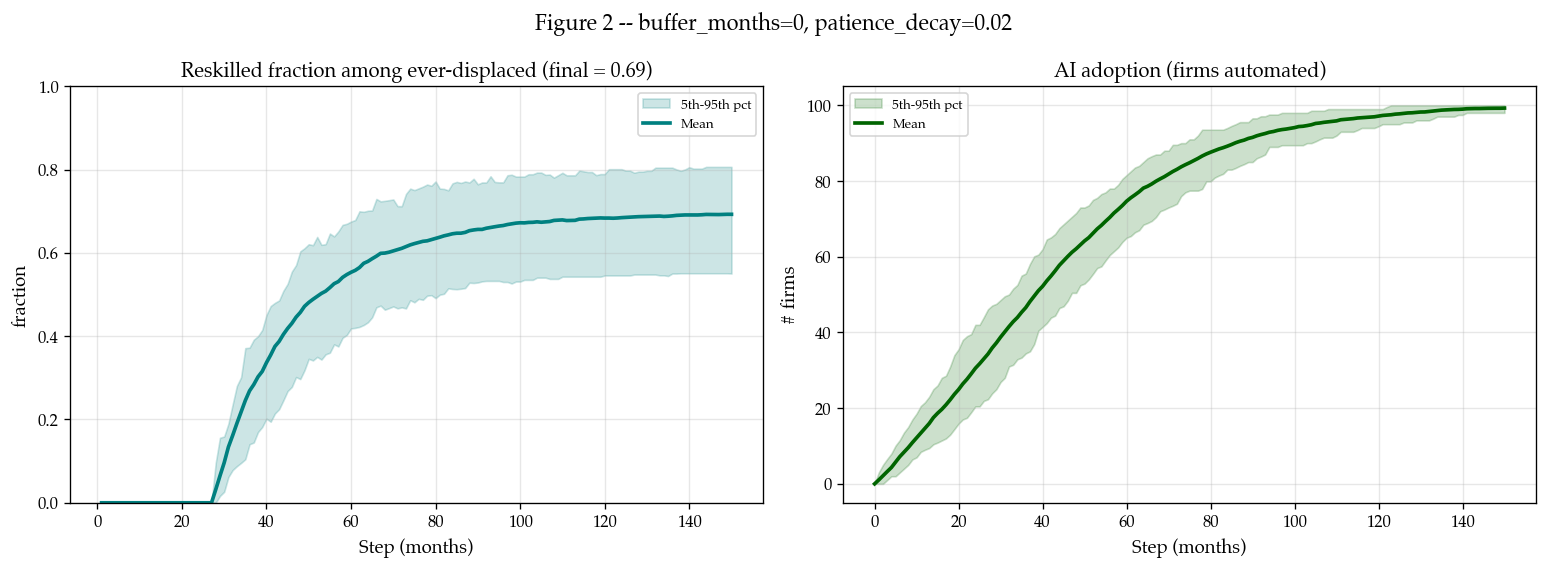

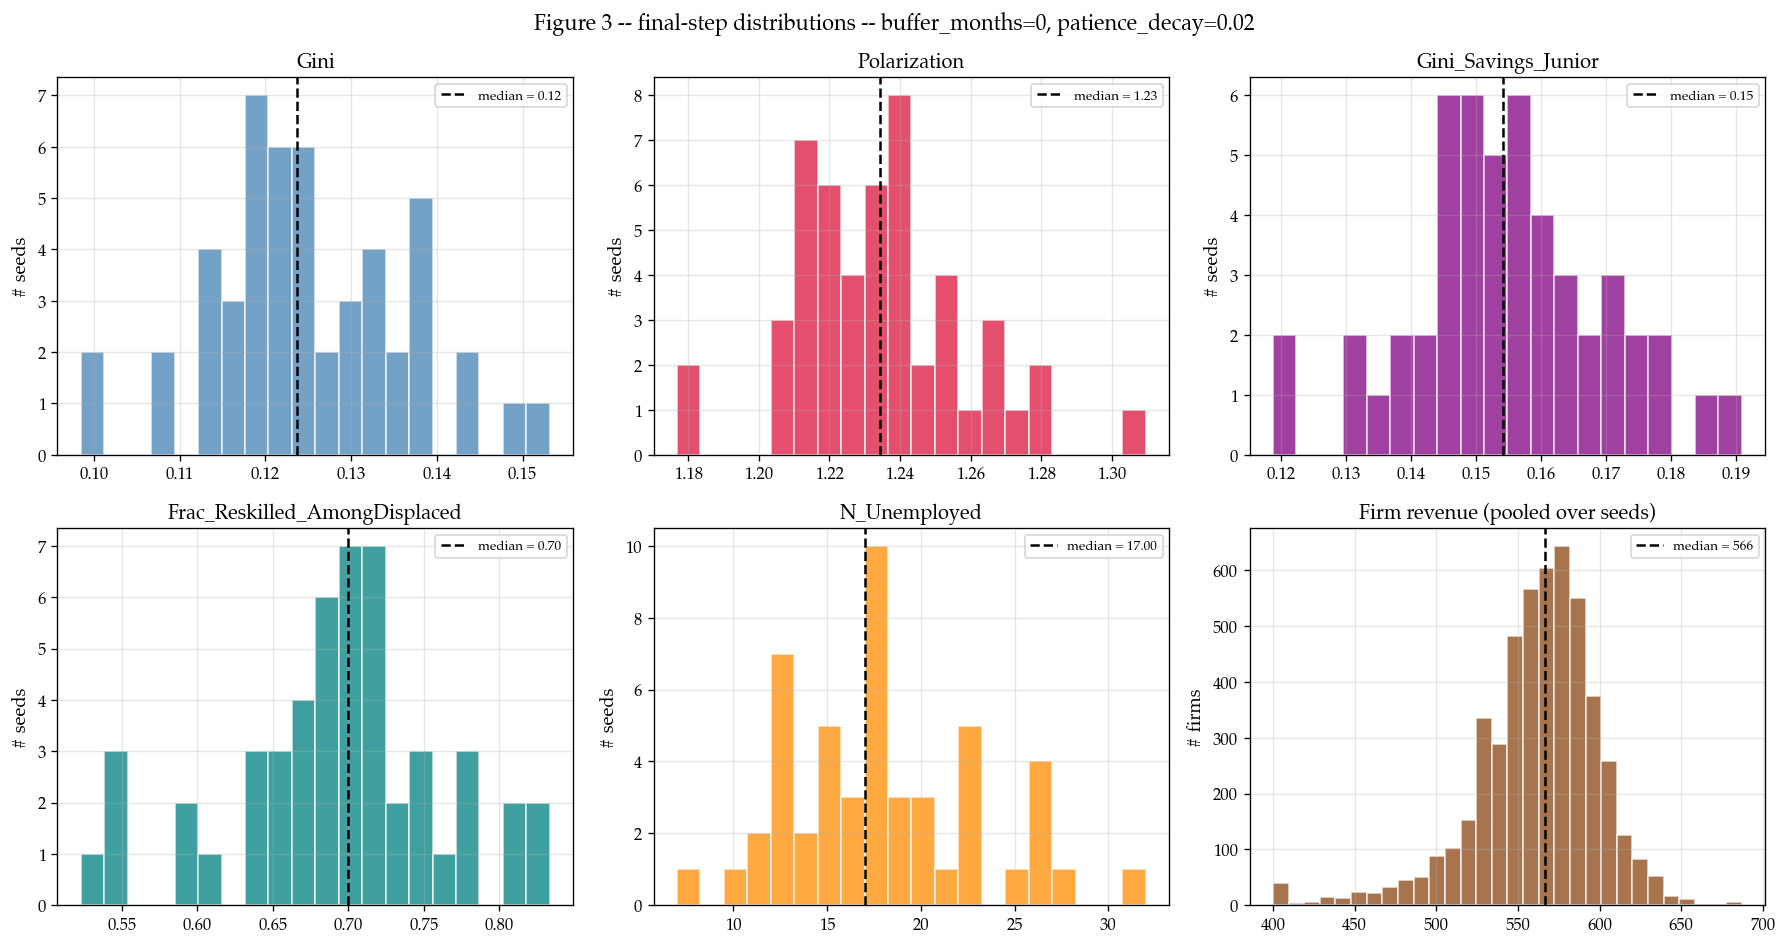

FINAL-STEP SUMMARY (step 150, 50 seeds) -- buffer_months=0, patience_decay=0.02
                     Variable     Mean      p05      p95
                         Gini   0.1249   0.1089   0.1439
                 Polarization   1.2345   1.2050   1.2771
          Gini_Savings_Junior   0.1546   0.1306   0.1782
                 N_Unemployed  17.8400  11.0000  26.0000
          Mean_Savings_Junior 528.6432 509.4636 540.8517
          Mean_Savings_Senior 652.3752 646.9865 657.5841
             Mean_Wage_Junior  22.3501  21.9304  22.6552
             Mean_Wage_Senior  22.7473  22.6131  22.8738
Frac_Reskilled_AmongDisplaced   0.6927   0.5505   0.8066
              Firms_Automated  99.2600  98.0000 100.0000


In [10]:
# Configuration grid: main specification first, then robustness variants
CONFIGS = [
    (3, 0.05, "Main spec (buffer_months=3, patience_decay=0.05)"),
    (3, 0.02, "buffer_months=3, patience_decay=0.02"),
    (0, 0.05, "buffer_months=0, patience_decay=0.05"),
    (0, 0.02, "buffer_months=0, patience_decay=0.02"),
]

for buffer_months, patience_decay, label in CONFIGS:
    print(label)
    s, res, firm_rev = run_mc(buffer_months, patience_decay)
    plot_mc(s, res, firm_rev, label)
